# Statistical process control for continuous manufacturing

This notebook replays one historical production run from a two-stage continuous-flow line. It follows Measurement 0 at each stage, fits limits on an earlier window, checks them on a separate window, then flags later observations against the frozen baseline. The historical alerts identify times to investigate. The separately labeled simulation gives the alarms known ground truth.

Run all cells from this folder. The data comes from the [published manufacturing dataset](https://www.kaggle.com/datasets/supergus/multistage-continuousflow-manufacturing-process). The notebook reads the bundled CSV and exports `spc_replay.png`.

## 1. Audit the data before monitoring

The two `.Actual` columns measure the same surface location after each stage. `.Setpoint` columns are engineering targets and appear as reference lines on a measurement plot. The [study of this dataset](https://link.springer.com/article/10.1186/s40537-020-00367-w) describes zero-coded erroneous output readings. Here, zero or nonfinite output readings, duplicate timestamp slots, and missing seconds become gaps. A setpoint of zero paired with a zero output is also shown as a gap because the target is ambiguous there. All rows at a duplicate timestamp are withheld because the file provides no rule for choosing one. No readings are imputed. Timestamps retain the clock in the source file.

In [1]:
from dataclasses import dataclass
from math import erfc, sqrt
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_PATH = Path("src/continuous_factory_process.csv")
CHANNELS = {
    "Stage 1": "Stage1.Output.Measurement0.U",
    "Stage 2": "Stage2.Output.Measurement0.U",
}
columns = [f"{channel}.{role}" for channel in CHANNELS.values() for role in ("Actual", "Setpoint")]
source = pd.read_csv(DATA_PATH, usecols=["time_stamp", *columns])
source["time_stamp"] = pd.to_datetime(
    source["time_stamp"], format="%Y-%m-%d %H:%M:%S", errors="raise"
)
if source.empty or source["time_stamp"].isna().any():
    raise ValueError("The input must contain a timestamp for every row.")

stamps = source["time_stamp"]
duplicates = stamps.duplicated(keep=False)
timeline = pd.date_range(stamps.min(), stamps.max(), freq="s", name="time_stamp")
measurements = source.loc[~duplicates].set_index("time_stamp").reindex(timeline)
measurements = measurements.apply(pd.to_numeric, errors="coerce")
actuals = pd.DataFrame(index=timeline)
targets = pd.DataFrame(index=timeline)
quality_rows = []
first_30 = timeline < timeline[0] + pd.Timedelta(minutes=30)
for stage, channel in CHANNELS.items():
    actual_column = f"{channel}.Actual"
    numeric = pd.to_numeric(source[actual_column], errors="coerce")
    values = measurements[actual_column]
    actuals[stage] = values.where(np.isfinite(values) & values.ne(0))
    target_column = f"{channel}.Setpoint"
    target = measurements[target_column]
    targets[stage] = target.where(np.isfinite(target) & ~(target.eq(0) & values.eq(0)))
    quality_rows.append({
        "Channel": stage,
        "Zero readings in source": int(numeric.eq(0).sum()),
        "Paired zero targets in source": int((numeric.eq(0) & pd.to_numeric(source[target_column], errors="coerce").eq(0)).sum()),
        "Nonfinite or nonnumeric in source": int((~np.isfinite(numeric)).sum()),
        "Usable readings on grid": int(actuals[stage].count()),
        "Usable first 30 minutes (%)": 100 * actuals.loc[first_30, stage].notna().mean(),
    })

print(f"{len(source):,} source rows, {len(timeline):,} one-second slots")
print(f"{duplicates.sum()} rows withheld at {stamps[duplicates].nunique()} duplicate timestamps, "
      f"{len(timeline) - stamps.nunique()} missing seconds")
display(pd.DataFrame(quality_rows).set_index("Channel").round(2))

14,088 source rows, 14,088 one-second slots
27 rows withheld at 13 duplicate timestamps, 14 missing seconds


,Zero readings in source,Paired zero targets in source,Nonfinite or nonnumeric in source,Usable readings on grid,Usable first 30 minutes (%)
Channel,,,,,
Stage 1,70,56,0,13991,99.28
Stage 2,1224,0,0,12840,56.11


## 2. Fit once and qualify on later observations

This retrospective case study sets aside the first 30 minutes because of limited early Stage 2 coverage. Minutes 30–50 fit each baseline, minutes 50–65 qualify it, and minute 65 onward is the replay. Each interval starts with fresh detector state and uses only adjacent one-second readings from its own interval. The file provides no operating-mode log, so these windows are case-study choices.

The chart monitors one-second forecast errors from a first-order autoregression (AR(1)). This uses the preceding measurement to forecast the current one. A gap breaks the pair. The calibration interval alone determines the model, the residual mean, and the residual standard deviation. The chart overlays fixed limits at ±3 baseline standard deviations. The dependence check compares the largest absolute correlation across lags 1–10 for raw readings and forecast errors. There is no documented sampling plan to justify treating every five rows as an X̄–R subgroup.

The explicit screening criteria are at least 80% valid forecast errors in both windows, qualification mean within 0.5 baseline standard deviations, scale ratio between 0.67 and 1.50, largest absolute residual autocorrelation at lags 1–10 at most 0.25, and at most 1% of qualification points outside the frozen limits. These are exploratory criteria. A failed screen is marked **provisional** and the offline replay can still illustrate the signals. See [NIST on Phase I and Phase II](https://www.itl.nist.gov/div898/handbook/pmc/section1/pmc12.htm) and [autocorrelation](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35c.htm).

In [2]:
@dataclass(frozen=True)
class Baseline:
    intercept: float
    phi: float
    center: float
    scale: float

    def score(self, values):
        errors = values - (self.intercept + self.phi * values.shift(1))
        return (errors - self.center) / self.scale


def fit_baseline(values):
    pairs = pd.concat([values.shift(1), values], axis=1).dropna().to_numpy()
    if len(pairs) < 100 or np.ptp(pairs[:, 0]) == 0:
        raise ValueError("Calibration needs at least 100 adjacent pairs and variation.")
    previous, current = pairs.T
    design = np.column_stack([np.ones(len(previous)), previous])
    intercept, phi = np.linalg.lstsq(design, current, rcond=None)[0]
    errors = current - design @ np.array([intercept, phi])
    scale = errors.std(ddof=1)
    numerical_floor = 10 * np.finfo(float).eps * max(1.0, np.max(np.abs(current)))
    if not np.isfinite(scale) or scale <= numerical_floor:
        raise ValueError("Calibration produced no usable residual variation.")
    return Baseline(intercept, phi, errors.mean(), scale)


def max_absolute_acf(values):
    correlations = pd.Series([values.autocorr(lag) for lag in range(1, 11)])
    return correlations.abs().max()


cal_start, fit_end, replay_start = [timeline[0] + pd.Timedelta(minutes=m) for m in (30, 50, 65)]
calibration = actuals.loc[(actuals.index >= cal_start) & (actuals.index < fit_end)]
qualification = actuals.loc[(actuals.index >= fit_end) & (actuals.index < replay_start)]
replay = actuals.loc[actuals.index >= replay_start]
if qualification.empty or replay.empty:
    raise ValueError("The input needs observations through the qualification and replay windows.")

baselines = {stage: fit_baseline(calibration[stage]) for stage in CHANNELS}
fit_scores = pd.DataFrame({stage: model.score(calibration[stage]) for stage, model in baselines.items()})
check_scores = pd.DataFrame({stage: model.score(qualification[stage]) for stage, model in baselines.items()})
replay_scores = pd.DataFrame({stage: model.score(replay[stage]) for stage, model in baselines.items()})
checks = []

for stage, model in baselines.items():
    fit_coverage = fit_scores[stage].notna().mean()
    z = check_scores[stage]
    coverage = z.notna().mean()
    mean, scale = z.mean(), z.std()
    residual_acf = max_absolute_acf(z)
    breach_rate = z.dropna().abs().gt(3).mean()
    criteria = {
        "coverage": min(fit_coverage, coverage) >= 0.80,
        "center": abs(mean) <= 0.50,
        "scale": 0.67 <= scale <= 1.50,
        "dependence": residual_acf <= 0.25,
        "3σ crossings": breach_rate <= 0.01,
    }
    checks.append({
        "Channel": stage,
        "AR(1) coefficient": model.phi,
        "Fit coverage (%)": fit_coverage * 100,
        "Check coverage (%)": coverage * 100,
        "Check mean (σ)": mean,
        "Check scale ratio": scale,
        "Check raw max |ACF|": max_absolute_acf(qualification[stage]),
        "Check residual max |ACF|": residual_acf,
        "Check 3σ crossings (%)": breach_rate * 100,
        "Status": "Screen passed" if all(criteria.values()) else "Provisional",
        "Failed checks": ", ".join(name for name, passed in criteria.items() if not passed) or "—",
    })

qualification_report = pd.DataFrame(checks).set_index("Channel")
print(f"Calibration: {cal_start:%H:%M:%S}–{fit_end:%H:%M:%S} (end exclusive)")
print(f"Qualification: {fit_end:%H:%M:%S}–{replay_start:%H:%M:%S} (end exclusive)")
display(qualification_report.round(3))
print("Capability: unavailable. The dataset provides targets but no documented engineering specifications.")

Calibration: 11:22:33–11:42:33 (end exclusive)
Qualification: 11:42:33–11:57:33 (end exclusive)


,AR(1) coefficient,Fit coverage (%),Check coverage (%),Check mean (σ),Check scale ratio,Check raw max |ACF|,Check residual max |ACF|,Check 3σ crossings (%),Status,Failed checks
Channel,,,,,,,,,,
Stage 1,0.961,99.750,95.000,0.077,0.820,0.947,0.197,1.170,Provisional,3σ crossings
Stage 2,0.857,98.667,98.333,0.124,0.995,0.379,0.300,1.243,Provisional,"dependence, 3σ crossings"


Capability: unavailable. The dataset provides targets but no documented engineering specifications.


## 3. Detect and audit replay alarms

The replay uses a two-sided 3σ alarm and a two-sided CUSUM. Both work in baseline-standardized forecast-error units. CUSUM resets on each alarm and at gaps. The eight Nelson tests run as diagnostics on the same fixed zones. Their output records the first signal in each uninterrupted run of qualifying windows, so a long run contributes one event per rule until that rule clears. Missing observations break the windows. Rule tests use [Nelson’s original definitions](https://doi.org/10.1080/00224065.1984.11978921).

The CUSUM threshold is selected on independent, simulated in-control runs to approximate the nominal two-sided 3σ alert rate. The same implementation and threshold score the replay and the labeled benchmark. See [NIST on CUSUM](https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc323.htm).

In [3]:
def nelson_events(values):
    """Return rule events for standardized values, with NaNs marking gaps."""
    z = pd.Series(values, dtype=float)

    def count(mask, size):
        return mask.astype(int).rolling(size, min_periods=size).sum()

    def same_side(size, required, band):
        full_window = count(z.notna(), size).eq(size)
        enough = count(z.gt(band), size).ge(required) | count(z.lt(-band), size).ge(required)
        return full_window & enough

    direction = np.sign(z.diff())
    alternating = direction.mul(direction.shift(1)).eq(-1)
    conditions = {
        1: z.abs().gt(3),
        2: same_side(9, 9, 0),
        3: count(direction.gt(0), 5).eq(5) | count(direction.lt(0), 5).eq(5),
        4: count(alternating, 12).eq(12),
        5: same_side(3, 2, 2),
        6: same_side(5, 4, 1),
        7: count(z.abs().le(1), 15).eq(15),
        8: count(z.abs().gt(1), 8).eq(8) & count(z.gt(1), 8).between(1, 7),
    }
    return {
        rule: active if rule == 1 else active & ~active.shift(1, fill_value=False)
        for rule, active in conditions.items()
    }


def three_sigma(values):
    valid = np.isfinite(values)
    return np.where(valid & (values > 3), 1, np.where(valid & (values < -3), -1, 0)).astype(np.int8)


def cusum(values, threshold, allowance=0.5):
    """Score trials by row and time by column, returning -1, 0, or +1."""
    scores = np.atleast_2d(np.asarray(values, dtype=float))
    signals = np.zeros_like(scores, dtype=np.int8)
    upper = np.zeros(scores.shape[0])
    lower = np.zeros(scores.shape[0])
    for i, sample in enumerate(scores.T):
        valid = np.isfinite(sample)
        sample = np.where(valid, sample, 0)
        upper = np.where(valid, np.maximum(0, upper + sample - allowance), 0)
        lower = np.where(valid, np.minimum(0, lower + sample + allowance), 0)
        crossed_upper = upper > threshold
        crossed_lower = lower < -threshold
        signals[:, i] = crossed_upper.astype(np.int8) - crossed_lower.astype(np.int8)
        reset = crossed_upper | crossed_lower
        upper[reset] = 0
        lower[reset] = 0
    return signals


def alerts_per_hour(signals):
    return np.count_nonzero(signals) / signals.size * 3600


def calibrate_cusum(null_values):
    nominal_rate = erfc(3 / sqrt(2)) * 3600
    low, high = 1.0, 12.0
    for _ in range(14):
        midpoint = (low + high) / 2
        if alerts_per_hour(cusum(null_values, midpoint)) > nominal_rate:
            low = midpoint
        else:
            high = midpoint
    return (low + high) / 2


calibration_rng = np.random.default_rng(4081)
CUSUM_THRESHOLD = calibrate_cusum(calibration_rng.standard_normal((2000, 900)))
print(f"CUSUM allowance k = 0.5, threshold h = {CUSUM_THRESHOLD:.3f}")

alarm_log = []
nelson_counts = {}
for stage in CHANNELS:
    z = replay_scores[stage]
    detectors = {"3σ": three_sigma(z.to_numpy()), "CUSUM": cusum(z, CUSUM_THRESHOLD)[0]}
    for detector, signals in detectors.items():
        for i in np.flatnonzero(signals):
            alarm_log.append({
                "Timestamp": z.index[i], "Stage": stage, "Detector": detector,
                "Direction": "Above" if signals[i] > 0 else "Below", "Forecast error (σ)": z.iloc[i],
            })
    nelson_counts[stage] = {rule: int(events.sum()) for rule, events in nelson_events(z).items()}

alarms = pd.DataFrame(alarm_log, columns=["Timestamp", "Stage", "Detector", "Direction", "Forecast error (σ)"])
alarms = alarms.sort_values(["Timestamp", "Stage", "Detector"]).reset_index(drop=True)
replay_summary = pd.DataFrame({
    "Valid scores": replay_scores.count(),
    "Replay coverage (%)": 100 * replay_scores.notna().mean(),
    "3σ alert count": alarms.loc[alarms["Detector"].eq("3σ"), "Stage"].value_counts().reindex(CHANNELS, fill_value=0),
    "CUSUM alert count": alarms.loc[alarms["Detector"].eq("CUSUM"), "Stage"].value_counts().reindex(CHANNELS, fill_value=0),
    "First alert": alarms.groupby("Stage")["Timestamp"].min().reindex(CHANNELS),
})
display(replay_summary.round({"Replay coverage (%)": 2}))
display(alarms.head(8).round({"Forecast error (σ)": 2}))
display(pd.DataFrame.from_dict(nelson_counts, orient="index").add_prefix("Rule "))

CUSUM allowance k = 0.5, threshold h = 4.737


,Valid scores,Replay coverage (%),3σ alert count,CUSUM alert count,First alert
Stage 1,10123,99.36,28,15,2019-03-06 11:58:24
Stage 2,9487,93.12,43,1,2019-03-06 12:07:47


,Timestamp,Stage,Detector,Direction,Forecast error (σ)
0,2019-03-06 11:58:24,Stage 1,3σ,Below,-6.50
1,2019-03-06 11:58:24,Stage 1,CUSUM,Below,-6.50
2,2019-03-06 11:58:26,Stage 1,3σ,Above,4.61
3,2019-03-06 12:01:35,Stage 1,3σ,Below,-3.49
4,2019-03-06 12:01:54,Stage 1,3σ,Below,-3.04
5,2019-03-06 12:01:57,Stage 1,3σ,Above,4.11
6,2019-03-06 12:02:01,Stage 1,3σ,Below,-3.18
7,2019-03-06 12:02:03,Stage 1,3σ,Above,3.78


,Rule 1,Rule 2,Rule 3,Rule 4,Rule 5,Rule 6,Rule 7,Rule 8
Stage 1,28,146,0,0,2,1,146,1
Stage 2,43,15,4,12,12,1,29,0


## 4. Verify rules and measure detection performance

The known-sequence checks cover exact trigger positions, boundary behavior, run resets, and both directions of the CUSUM. The performance benchmark uses a new random seed and independent standard-normal forecast errors at a one-second cadence. It measures false alerts on separate, entirely in-control runs. Shift trials add a sustained ±0.5σ, ±1σ, or ±2σ offset to the charted forecast errors after a 60-second warm-up. Detection means a signal in the correct direction within 120 seconds. Delay is measured from the first affected sample (a same-sample alert has delay zero) and the median is taken over detections. The shifts are injected into the scores, so the benchmark measures detector behavior under controlled conditions. The historical run has no labeled defects or independently verified alarm outcomes.

In [4]:
def event_positions(values, rule):
    return np.flatnonzero(nelson_events(values)[rule]).tolist()


assert event_positions([3, -3, 3.01, -3.01], 1) == [2, 3]
assert event_positions([0] + [0.25] * 10, 2) == [9]
assert event_positions([0.25] * 5 + [np.nan] + [0.25] * 5, 2) == []
assert event_positions(range(6), 3) == [5]
assert event_positions([1, 0] * 7, 4) == [13]
assert event_positions([1, 0] * 6 + [1], 4) == []
assert event_positions([2.1, 0, 2.1], 5) == [2]
assert event_positions([2.1, np.nan, 2.1], 5) == []
assert event_positions([-1.1, -1.1, 0, -1.1, -1.1], 6) == [4]
assert event_positions([0.25] * 16, 7) == [14]
assert event_positions([2.0] * 8, 8) == []
assert event_positions([2.0] * 7 + [-2.0], 8) == [7]
assert cusum([[2, 2, 2, 2], [-2, -2, -2, -2]], 2).tolist() == [[0, 1, 0, 1], [0, -1, 0, -1]]
assert cusum([2, np.nan, 2], 2).tolist() == [[0, 0, 0]]

probe = calibration["Stage 1"].iloc[:120].copy()
probe.iloc[30] = np.nan
probe_baseline = baselines["Stage 1"]
assert probe_baseline.score(probe).iloc[30:32].isna().all()
prefix = probe_baseline.score(probe.iloc[:60])
pd.testing.assert_series_equal(prefix, probe_baseline.score(probe).iloc[:60])
print("Known-sequence and replay boundary checks passed.")

validation_rng = np.random.default_rng(5029)
null_trials = validation_rng.standard_normal((3000, 900))
detectors = {"3σ": three_sigma, "CUSUM": lambda values: cusum(values, CUSUM_THRESHOLD)}
null_rates = {name: alerts_per_hour(detect(null_trials)) for name, detect in detectors.items()}
display(pd.DataFrame.from_dict(null_rates, orient="index", columns=["False alerts per hour"]).round(2))

warmup_s, horizon_s = 60, 120
shift_trials = validation_rng.standard_normal((3000, warmup_s + horizon_s))
directions = np.where(np.arange(len(shift_trials)) % 2 == 0, 1, -1)
results = []
for size in (0.5, 1.0, 2.0):
    shifted = shift_trials.copy()
    shifted[:, warmup_s:] += size * directions[:, None]
    for name, detect in detectors.items():
        matches = detect(shifted)[:, warmup_s:] == directions[:, None]
        detected = matches.any(axis=1)
        delay = matches[detected].argmax(axis=1)
        results.append({
            "Shift magnitude (σ)": size,
            "Detector": name,
            "Detected within 120 s (%)": 100 * detected.mean(),
            "Median detection delay (s)": np.median(delay) if delay.size else np.nan,
        })

validation = pd.DataFrame(results).set_index(["Shift magnitude (σ)", "Detector"])
display(validation.round(2))

Known-sequence and replay boundary checks passed.


,False alerts per hour
3σ,9.74
CUSUM,9.81


Detected within 120 s (%)  \
Shift magnitude (σ) Detector                              
0.5                 3σ                            51.83   
                    CUSUM                         98.57   
1.0                 3σ                            93.13   
                    CUSUM                        100.00   
2.0                 3σ                           100.00   
                    CUSUM                        100.00   

                              Median detection delay (s)  
Shift magnitude (σ) Detector                              
0.5                 3σ                              50.0  
                    CUSUM                           23.0  
1.0                 3σ                              29.0  
                    CUSUM                            7.0  
2.0                 3σ                               4.0  
                    CUSUM                            2.0

## 5. Export the portfolio replay chart

The chart focuses on Stage 1 near the qualification/replay boundary. It marks the first replay alert (3σ or CUSUM) and records an operator’s first check. The portfolio image includes the baseline status. The Stage 2 replay remains visible in the notebook’s audit tables.

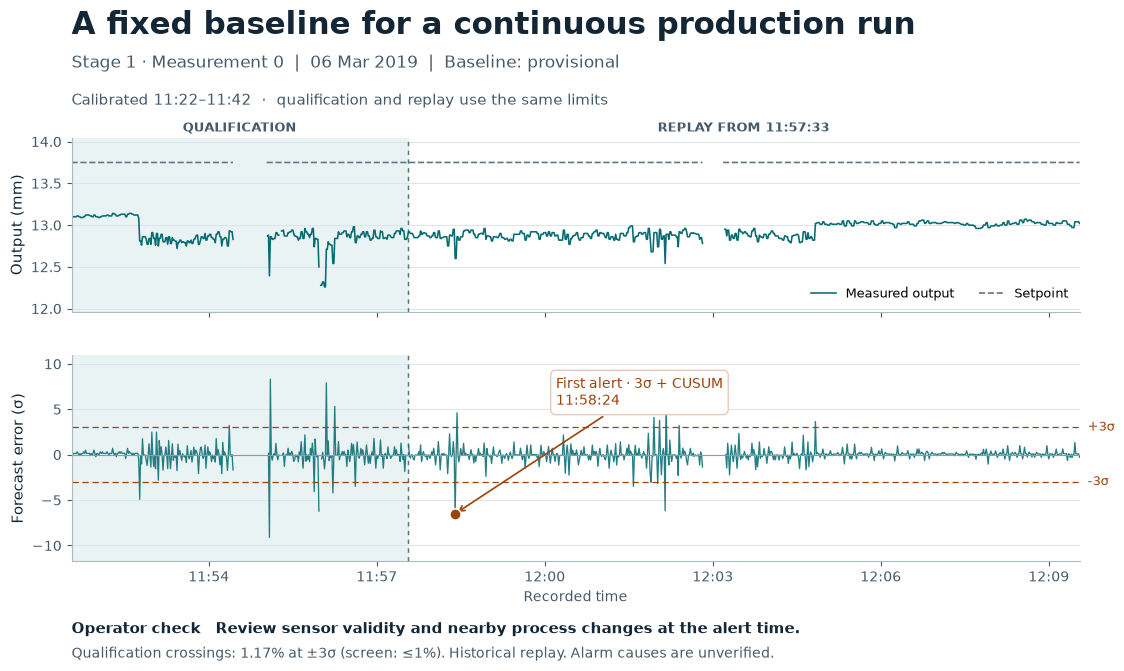

In [5]:
stage = "Stage 1"
first_alerts = alarms.loc[alarms["Stage"].eq(stage)]
first_alert = None if first_alerts.empty else first_alerts.iloc[0]
left = replay_start - pd.Timedelta(minutes=6)
right = replay_start + pd.Timedelta(minutes=12)
if first_alert is not None:
    right = max(right, first_alert["Timestamp"] + pd.Timedelta(minutes=2))
right = min(right, timeline[-1])

ink, muted = "#132636", "#465A6A"
teal, amber, light = "#066C72", "#9D430E", "#EAF3F3"
fig, (ax_actual, ax_score) = plt.subplots(2, 1, sharex=True, figsize=(12, 7),
                                          gridspec_kw={"height_ratios": [1, 1.18]})
fig.subplots_adjust(left=0.105, right=0.945, top=0.79, bottom=0.185, hspace=0.23)
fig.text(0.105, 0.938, "A fixed baseline for a continuous production run", fontsize=22, color=ink, weight="bold")
status = qualification_report.loc[stage, "Status"]
fig.text(0.105, 0.89, f"Stage 1 · Measurement 0  |  {timeline[0]:%d %b %Y}  |  Baseline: {status.lower()}",
         fontsize=12, color=muted)
fig.text(0.105, 0.837, f"Calibrated {cal_start:%H:%M}–{fit_end:%H:%M}  ·  qualification and replay use the same limits",
         fontsize=10.5, color=muted)

for ax in (ax_actual, ax_score):
    ax.axvspan(left, replay_start, color=light, zorder=0)
    ax.axvline(replay_start, color="#577281", linewidth=1.05, linestyle=(0, (3, 3)), zorder=2)
    ax.grid(axis="y", color="#DCE5E9", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#AABAC3")
    ax.tick_params(colors=muted, labelsize=10)

ax_actual.plot(actuals.loc[left:right, stage], color=teal, lw=1.15, label="Measured output")
ax_actual.plot(targets.loc[left:right, stage], color="#647684", lw=1.2, ls="--", label="Setpoint")
ax_actual.set_ylabel("Output (mm)", color=ink, size=11)
ax_actual.margins(y=0.20)
ax_actual.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="none", ncols=2, fontsize=9)
top_labels = ax_actual.get_xaxis_transform()
ax_actual.text(left + (replay_start - left) / 2, 1.035, "QUALIFICATION", transform=top_labels,
               ha="center", color=muted, fontsize=9, weight="bold")
ax_actual.text(replay_start + (right - replay_start) / 2, 1.035, f"REPLAY FROM {replay_start:%H:%M:%S}",
               transform=top_labels, ha="center", color=muted, fontsize=9, weight="bold")

score = pd.concat([check_scores[stage], replay_scores[stage]]).loc[left:right]
ax_score.plot(score, color=teal, linewidth=0.95, alpha=0.88)
ax_score.axhline(0, color="#899CA7", linewidth=0.8)
for limit in (-3, 3):
    ax_score.axhline(limit, color=amber, linewidth=0.9, linestyle=(0, (5, 3)))
    ax_score.text(1.008, limit, f"{limit:+}σ", transform=ax_score.get_yaxis_transform(),
                  color=amber, va="center", fontsize=9)
ax_score.set_ylabel("Forecast error (σ)", color=ink, size=11)
ax_score.set_xlim(left, right)
ax_score.margins(y=0.15)
locator = mdates.AutoDateLocator(minticks=6, maxticks=9)
locator.intervald[mdates.MINUTELY] = [1, 2, 3, 5, 10, 15, 30]
ax_score.xaxis.set_major_locator(locator)
ax_score.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax_score.set_xlabel("Recorded time", color=muted, fontsize=10)

if first_alert is not None:
    alert_time = first_alert["Timestamp"]
    alert_value = first_alert["Forecast error (σ)"]
    ax_score.scatter(alert_time, alert_value, s=66, color=amber, edgecolor="white", linewidth=1.15, zorder=5)
    detector_names = " + ".join(first_alerts.loc[first_alerts["Timestamp"].eq(alert_time), "Detector"])
    label_time = min(alert_time + (right - left) * 0.10, left + (right - left) * 0.70)
    ax_score.annotate(f"First alert · {detector_names}\n{alert_time:%H:%M:%S}",
                      xy=(alert_time, alert_value), xytext=(label_time, 0.82),
                      textcoords=ax_score.get_xaxis_transform(), fontsize=10, va="center", color=amber,
                      bbox={"boxstyle": "round,pad=0.38", "fc": "white", "ec": "#E7C9B8"},
                      arrowprops={"arrowstyle": "->", "color": amber, "linewidth": 1.2})

fig.text(0.105, 0.082, "Operator check   Review sensor validity and nearby process changes at the alert time.",
         color=ink, fontsize=11, weight="bold")
crossing_rate = qualification_report.loc[stage, "Check 3σ crossings (%)"]
note = f"Qualification crossings: {crossing_rate:.2f}% at ±3σ (screen: ≤1%). "
fig.text(0.105, 0.047, note + "Historical replay. Alarm causes are unverified.", color=muted, fontsize=10)
fig.savefig("spc_replay.png", dpi=200, facecolor="white")
plt.show()

The next investigation would compare timestamps with sensor-maintenance and operating-mode records. Longer runs with known operating states would support site-specific calibration and prospective validation. Engineering specifications and evidence of a stable process would be needed for a capability study.